# Analiza eksploracyjna sygnałów
Celem notatnika jest analiza eksploracyjna sygnałów polisomnograficznych pacjentów, której wynikiem będzie podział danych na zbiór treningowy, walidacyjny i testowy oraz zbadanie jakości sygnałów. Jakość sygnałów będzie określana na podstawie metod statystycznych i ma na celu wykrycie epok, w których występują artefakty sprzętowe np. odłączenie elektrody.
Główne cele notatnika:
- sprawdzenie ilości badań na pacjenta oraz na jednostkę szpitalną;
- sprawdzenie rozkładu zmiennej opisywanej na tle innyh cech;
- podział zbioru na treningowy, walidacyjny i testowy;
- sprawdzenie jakości poszczególnych sygnałów i wyznaczenie konkretnych metryk statystycznych definiujących czy kanał będzi ebrany do dalszej analizy.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42

SILVER_DIR = Path("/home/emil/studia/inzynierka/data/silver")
SPLITS_DIR = Path("/home/emil/studia/inzynierka/references")
DEMOGRAPHICS_CSV = SILVER_DIR / "demographics.csv"

## 1. Analiza metadanych
Ta część notatnika ma na celu sprawdzenie ilu średnio badaniom byli poddawani pacjenci, ilu pacjentów przypadało na dany ośrodek oraz ogólny przegląd metadanych z pliku demographics.csv. 
### 1.1 Przegląd braków

In [2]:
demo = pd.read_csv(DEMOGRAPHICS_CSV)
missing = pd.DataFrame({"n_braki": demo.isna().sum()})
missing["odsetek_%"] = (100 * missing["n_braki"] / len(demo)).round(2)
missing

,n_braki,odsetek_%
SiteID,0,0.0
BDSPPatientID,0,0.0
CreationTime,0,0.0
BidsFolder,0,0.0
SessionID,0,0.0
Age,0,0.0
Sex,0,0.0
Race,0,0.0
Ethnicity,0,0.0
BMI,214,36.9


Metadane w zbiorze zawierają braki w kolumnie BMI (36.9%) i będą one musiały zostać uzupełnione. Braki w kolumnie Time_to_event wynikają z faktu, że połowa pacjentów w zbiorze to próba kontrolna, która nie ma zaburzeń kognitywistycznych.

## 1.2 Liczba badań na pacjenta

In [3]:
one_row_per_patient = pd.DataFrame({
    "wartosc": [len(demo), demo["BDSPPatientID"].nunique(),
                demo.groupby(["SiteID", "BDSPPatientID"]).ngroups]
}, index=["wierszy", "unikalnych_BDSPPatientID", "unikalnych_(Site,Pacjent)"])
one_row_per_patient

,wartosc
wierszy,580
unikalnych_BDSPPatientID,580
"unikalnych_(Site,Pacjent)",580


In [4]:
(demo["SessionID"].value_counts().sort_index()
 .rename_axis("SessionID").rename("liczba_pacjentow").to_frame())

,liczba_pacjentow
SessionID,
1,533
2,30
3,15
4,1
7,1


Okazuje się, że wszystkie badania w zbiorze zostały wykonane dla unikalnych pacjentów. Identyfikatory sesji nie służą do oznaczenia kolejnych nagrań pacjenta, a służą jedynie do znalezienia odpowiedniego badania z ustandaryzowaną nazwą, w której znajduje się nr sesji.

## 1.3 Pokrycie placówek

In [5]:
site_coverage = (demo["SiteID"].value_counts()
                 .rename_axis("SiteID").rename("liczba_pacjentow").to_frame())
site_coverage["odsetek_%"] = (100 * site_coverage["liczba_pacjentow"] / len(demo)).round(2)
site_coverage

,liczba_pacjentow,odsetek_%
SiteID,,
S0001,448,77.24
I0006,99,17.07
I0002,33,5.69


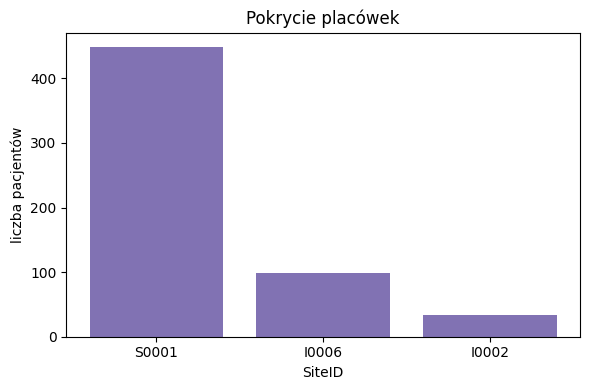

In [6]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(site_coverage.index.astype(str), site_coverage["liczba_pacjentow"], color="#8172B3")
ax.set_xlabel("SiteID")
ax.set_ylabel("liczba pacjentów")
ax.set_title("Pokrycie placówek")
plt.tight_layout()
plt.show()

Pod kątem placówek zbiór jest silnie niezbalansowany. Zdecydowana większośść badań pochodzi z jednej placówki o sygnaturze S0001. Pozostałe placówki stanowią jedynie uzupełnienie zbioru

## 1.4 Zaburzenia kognitywistyczne 

In [7]:
target_counts = (demo["Cognitive_Impairment"].value_counts(dropna=False)
                 .rename_axis("Cognitive_Impairment")
                 .rename("liczba_pacjentow").to_frame())
target_counts["odsetek_%"] = (100 * target_counts["liczba_pacjentow"] / len(demo)).round(2)
target_counts

,liczba_pacjentow,odsetek_%
Cognitive_Impairment,,
True,290,50.0
False,290,50.0


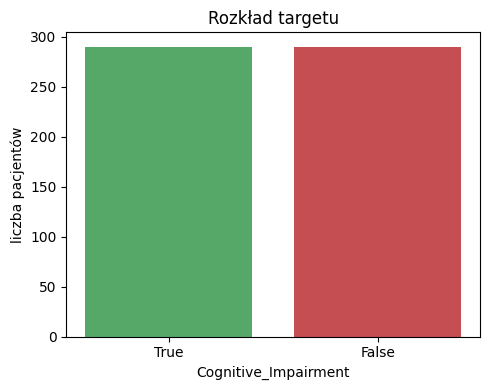

In [8]:
fig, ax = plt.subplots(figsize=(5, 4))
order = target_counts.index.astype(str)
ax.bar(order, target_counts["liczba_pacjentow"], color=["#55A868", "#C44E52"])
ax.set_xlabel("Cognitive_Impairment")
ax.set_ylabel("liczba pacjentów")
ax.set_title("Rozkład targetu")
plt.tight_layout()
plt.show()

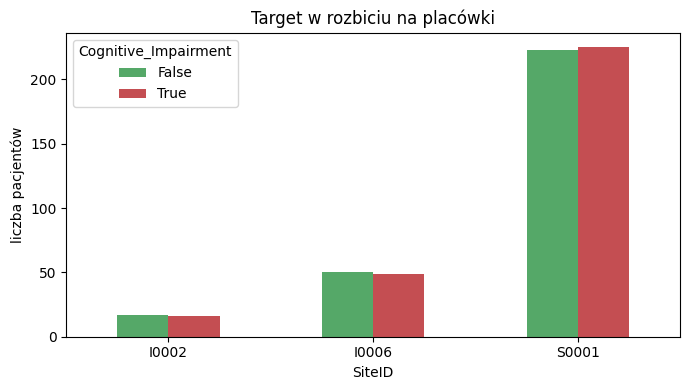

In [9]:
site_target = pd.crosstab(demo["SiteID"], demo["Cognitive_Impairment"])
ax = site_target.plot(kind="bar", figsize=(7, 4), color=["#55A868", "#C44E52"])
ax.set_xlabel("SiteID")
ax.set_ylabel("liczba pacjentów")
ax.set_title("Target w rozbiciu na placówki")
ax.legend(title="Cognitive_Impairment")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Tak jak zapewniał autor zbioru, jest on w pełni zbalansowany pod względem występowania zaburzeń poznawczych. Każda placówka posiada tyle samo pacjentów chorych i zdrowych. Jest to bardzo dobra informacja dla zbioru uczącego, bo gwarantuje, że model nie nauczy się rozpoznawać placówki a patologie. Dodatkowo zapewni zbalansowany podział na zbiór uczący, walidacyjny i testowy.

## 1.5 Wiek (Age)

In [10]:
demo["Age"].describe()

count    580.000000
mean      69.870690
std        8.557769
min       50.000000
25%       64.000000
50%       70.000000
75%       76.000000
max       89.000000
Name: Age, dtype: float64

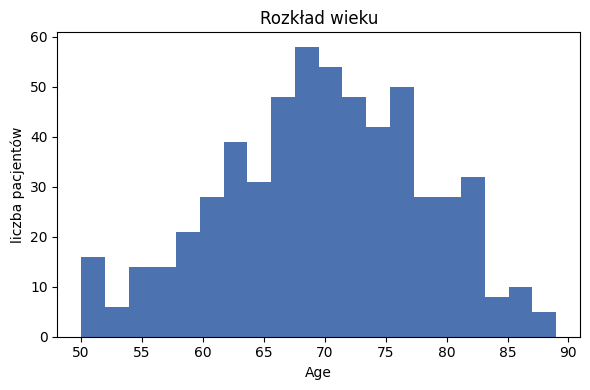

In [11]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(demo["Age"], bins=20, color="#4C72B0")
ax.set_xlabel("Age")
ax.set_ylabel("liczba pacjentów")
ax.set_title("Rozkład wieku")
plt.tight_layout()
plt.show()

In [12]:
demo.groupby("Cognitive_Impairment")["Age"].describe()

,count,mean,std,min,25%,50%,75%,max
Cognitive_Impairment,,,,,,,,
False,290.0,69.755172,8.591784,50.0,64.0,70.0,76.00,89.0
True,290.0,69.986207,8.536902,50.0,64.0,70.0,76.75,88.0


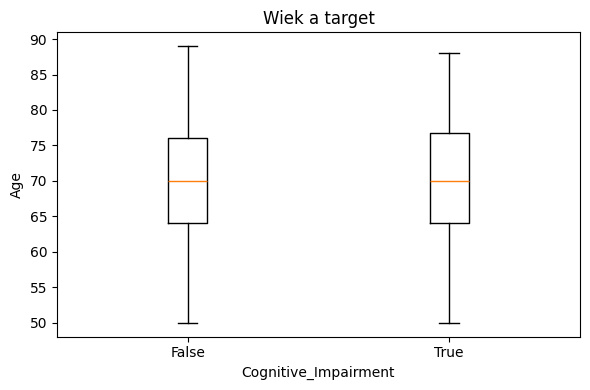

In [13]:
fig, ax = plt.subplots(figsize=(6, 4))
groups = [demo.loc[demo["Cognitive_Impairment"] == v, "Age"] for v in [False, True]]
ax.boxplot(groups, tick_labels=["False", "True"])
ax.set_xlabel("Cognitive_Impairment")
ax.set_ylabel("Age")
ax.set_title("Wiek a target")
plt.tight_layout()
plt.show()

Wiek jest kolejną świetnie zbalansowaną zmienną. Jest to kolejna świetna informacja dla danych w zbiorze. Sprawia to, że wiek nie będzie wprowadzał zbędnego szumu w danych.

## 1.6 Płeć (Sex)

In [14]:
sex_counts = (demo["Sex"].value_counts(dropna=False)
              .rename_axis("Sex").rename("liczba_pacjentow").to_frame())
sex_counts["odsetek_%"] = (100 * sex_counts["liczba_pacjentow"] / len(demo)).round(2)
sex_counts

,liczba_pacjentow,odsetek_%
Sex,,
Male,335,57.76
Female,245,42.24


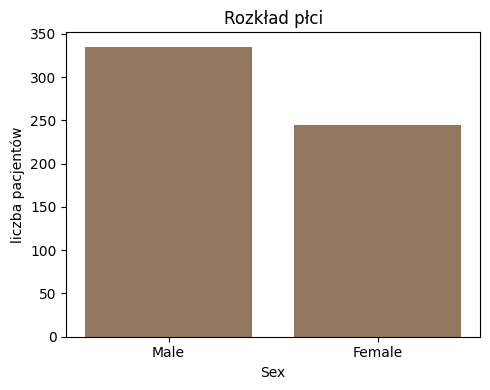

In [15]:
fig, ax = plt.subplots(figsize=(5, 4))
vc = demo["Sex"].value_counts()
ax.bar(vc.index, vc.values, color="#937860")
ax.set_xlabel("Sex")
ax.set_ylabel("liczba pacjentów")
ax.set_title("Rozkład płci")
plt.tight_layout()
plt.show()

In [16]:
pd.crosstab(demo["Sex"], demo["Cognitive_Impairment"], normalize="index").mul(100).round(2)

Cognitive_Impairment,False,True
Sex,,
Female,50.61,49.39
Male,49.55,50.45


W przypadku płci zbiór już nie jest tak ściśle zbalansowany jak w przypadku poprzednich zmiennych, jednakże płcie są zbalansowane pod kątem występowania zaburzeń poznawczych. Oznacza to, że również i ta zmienna nie powinna wprowadzić szumu związanego z niezbalansowanymi klasami.

## 1.7 Rasa i pochodzenie etniczne (Race, Ethnicity)

In [17]:
(demo["Race"].value_counts(dropna=False)
 .rename_axis("Race").rename("liczba_pacjentow").to_frame())

,liczba_pacjentow
Race,
White,473
Black,64
Asian,15
Others,15
Unavailable,13


In [18]:
(demo["Ethnicity"].value_counts(dropna=False)
 .rename_axis("Ethnicity").rename("liczba_pacjentow").to_frame())

,liczba_pacjentow
Ethnicity,
Not Hispanic,531
Unavailable,32
Hispanic,17


In [19]:
pd.crosstab(demo["Race"], demo["Cognitive_Impairment"], normalize="index").mul(100).round(2)

Cognitive_Impairment,False,True
Race,,
Asian,46.67,53.33
Black,48.44,51.56
Others,46.67,53.33
Unavailable,23.08,76.92
White,51.16,48.84


In [20]:
pd.crosstab(demo["Ethnicity"], demo["Cognitive_Impairment"], normalize="index").mul(100).round(2)

Cognitive_Impairment,False,True
Ethnicity,,
Hispanic,41.18,58.82
Not Hispanic,49.34,50.66
Unavailable,65.62,34.38


Rasa i pochodzenie etniczne również jest zbalansowane pod względem zaburzeń, jednak nie dla pacjentów, u których dana cecha jest nieokreślona.

## 1.8 BMI

In [21]:
demo["BMI"].describe()

count    366.000000
mean      29.831421
std        6.568252
min       18.110000
25%       25.082500
50%       28.645000
75%       33.520000
max       71.540000
Name: BMI, dtype: float64

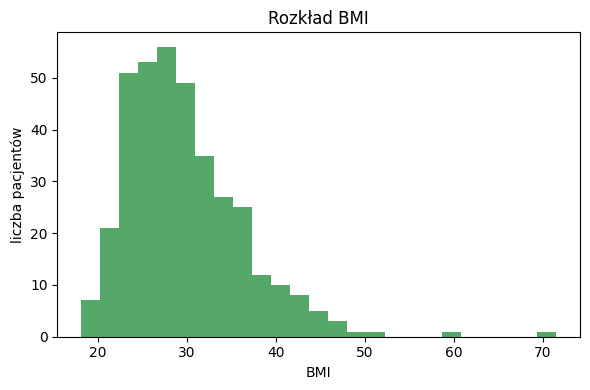

In [22]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(demo["BMI"].dropna(), bins=25, color="#55A868")
ax.set_xlabel("BMI")
ax.set_ylabel("liczba pacjentów")
ax.set_title("Rozkład BMI")
plt.tight_layout()
plt.show()

Rozkład BMI jest rozkładem prawoskośnym, występuje kilku pacjentów o bardzo wysokim BMI. Pod względem zaburzeń jest on zbalansowany jak każda inna zmienna w zbiorze. Dodatkowo w tej zmiennej występuje wiele braków, co sprawia, że nie jest to dobra cecha opisująca.

## 1.9 Podsumowanie
Wszystkie cechy znajdujące się w pliku demographics.csv są bardzo dobrze zbalansowana. Oznacza to, że zbiór jest świetnie przygotowany pod analizę wpływu samych parametrów zmierzonych podczas badania. Model lepiej będzie rozpoznawał cechy związane z samymi zaburzeniami poznawczymi a nie z wiekiem czy płcią. Jest to bardzo duże ułatwienie i pozwala podzielić zbiór tylko i wyłącznie pod względem cechy opisywanej i nie będzie wymagał sztucznego balansowania klas. Niestety niesie to też za sobą zagrożenie związane z tym, że jeśli model nauczony na takich danych będzie później używany do przewidywania, nie będzie on brał pod uwagę żadnej z tych cech, mimo że w prawdziwym życiu mogą one nieść za sobą jakąś informację. Cechy te same w sobie nie będą rozróżniać pacjentów chorych od zdrowych, ale mogą wchodzić w interakcje z cechami sygnałowymi, dlatego decyzja o włączeniu cech demograficznych do modelu zostaje odłożona do fazy modelowania. Dodatkowo BMI zawiera wiele braków i będzie musiało zostać uzupełnione w sposób sztuczny.

# 2. Podział pacjentów na zbiory uczący, walidacyjny i testowy (70/15/15)

Podział głównego zbioru jest zamrażany przed wykonaniem analizy związku cech sygnału z targetem.

Założenia podziału:
- Proporcje 70 / 15 / 15: trening / walidacja / test.
- Podział po Cognitive_Impairment i placówce ze względu na dysproporjcę w tej cesze.
- Jeden podział na trzy części naraz.

## 2.1 Definicja klucza podziału
Jest potrzbena, żeby zachować balans między poszczególnymi placówkami. Celem jest uniknięcie sytuacji, w której cały zbiór uczący jest z jednej placówki a zbiór testowy z drugiej.

In [23]:
demo["strata"] = (demo["SiteID"].astype(str) + " | "
                  + demo["Cognitive_Impairment"].astype(str))
strata_counts = demo["strata"].value_counts().sort_index()
strata_counts

strata
I0002 | False     17
I0002 | True      16
I0006 | False     50
I0006 | True      49
S0001 | False    223
S0001 | True     225
Name: count, dtype: int64

## 2.2 Wykonanie podziału

In [24]:
def stratified_three_way_split(strata_labels, ids, props=(0.70, 0.15, 0.15),
                                names=("train", "val", "test"), seed=0):
    props = np.asarray(props, dtype=float)
    rng = np.random.default_rng(seed)
    assignment = np.empty(len(ids), dtype=object)

    for stratum in np.unique(strata_labels):
        idx = np.where(strata_labels == stratum)[0]
        idx_shuffled = rng.permutation(idx)
        n = len(idx_shuffled)

        n_val = int(np.floor(n * props[1]))
        n_test = int(np.floor(n * props[2]))
        n_train = n - n_val - n_test

        assignment[idx_shuffled[:n_train]] = names[0]
        assignment[idx_shuffled[n_train:n_train + n_val]] = names[1]
        assignment[idx_shuffled[n_train + n_val:]] = names[2]

    return assignment

In [25]:
demo["patient_id"] = demo["BidsFolder"]
demo["split"] = stratified_three_way_split(
    strata_labels=demo["strata"].to_numpy(),
    ids=demo["patient_id"].to_numpy(),
    props=(0.70, 0.15, 0.15),
    names=("train", "val", "test"),
    seed=SEED,
)
demo["split"].value_counts()

split
train    412
test      84
val       84
Name: count, dtype: int64

## 2.3 Weryfikacja
W tym podrozdziale zostanie sprawdzone czy podział został wykonany równomiernie względem różnych cech.

In [26]:
site_split = pd.crosstab(demo["SiteID"], demo["split"]).reindex(
    columns=["train", "val", "test"]
)
site_split["total"] = site_split.sum(axis=1)
site_split

split,train,val,test,total
SiteID,,,,
I0002,25,4,4,33
I0006,71,14,14,99
S0001,316,66,66,448


In [27]:
(pd.crosstab(demo["SiteID"], demo["split"], normalize="index")
 .reindex(columns=["train", "val", "test"]).mul(100).round(2))

split,train,val,test
SiteID,,,
I0002,75.76,12.12,12.12
I0006,71.72,14.14,14.14
S0001,70.54,14.73,14.73


In [28]:
pd.crosstab(demo["split"], demo["Cognitive_Impairment"]).reindex(["train", "val", "test"])

Cognitive_Impairment,False,True
split,,
train,206,206
val,42,42
test,42,42


In [29]:
(pd.crosstab(demo["split"], demo["Cognitive_Impairment"], normalize="index")
 .reindex(["train", "val", "test"]).mul(100).round(2))

Cognitive_Impairment,False,True
split,,
train,50.0,50.0
val,50.0,50.0
test,50.0,50.0


In [30]:
(pd.crosstab(demo["split"], demo["Sex"], normalize="index")
 .reindex(["train", "val", "test"]).mul(100).round(2))

Sex,Female,Male
split,,
train,41.99,58.01
val,42.86,57.14
test,42.86,57.14


In [31]:
demo.groupby("split")["Age"].describe().reindex(["train", "val", "test"])

,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
train,412.0,70.092233,8.532533,50.0,64.00,70.0,76.25,89.0
val,84.0,68.845238,9.087916,50.0,63.00,68.5,75.00,89.0
test,84.0,69.809524,8.152871,50.0,65.75,70.0,75.00,86.0


## 2.4 Zapis podziału

In [32]:
assign_cols = ["patient_id", "SiteID", "BDSPPatientID", "SessionID", "Cognitive_Impairment", "split"]
assignments = demo[assign_cols].sort_values(["split", "patient_id"]).reset_index(drop=True)
assignments.to_csv(SPLITS_DIR / "assignments.csv", index=False)

split_payload = {
    "seed": SEED,
    "proportions": {"train": 0.70, "val": 0.15, "test": 0.15},
    "granularity": "patient",
    "stratify_by": ["SiteID", "Cognitive_Impairment"],
    "n_total": int(len(demo)),
    "sizes": {k: int(v) for k, v in demo["split"].value_counts().items()},
    "splits": {
        name: sorted(demo.loc[demo["split"] == name, "patient_id"].tolist())
        for name in ("train", "val", "test")
    },
}
(SPLITS_DIR / "split.json").write_text(json.dumps(split_payload, indent=2, ensure_ascii=False))
print(f"Zapisano: assignments.csv ({len(assignments)} wierszy), split.json")

Zapisano: assignments.csv (580 wierszy), split.json


## 2.4 Podsumowanie
Podział zbioru na treningowy, walidacyjny i testowy został wykonany poprawnie. W każdym ze zbiorów cechy rozłożyły się względnie równomiernie, w proporcjach zachowanych z pełnego zbioru. W każdym zbiorze liczba pacjentów chorych i zdrowych jest taka sama. Rozkład płci jest delikatnie nierównomierny na rzecz mężczyzn, jednak jest to wynik tego, że zbiór pierwotny również zawierał taką nierównomierność. Stratyfikacja po placówce zapewniła, że każda placówka zachowała swoje proporcje (chorych/zdrowych) w każdym zbiorze  Placówka z najmniejszą ilością danych została podzielona najgorzej ze względu na małą ilość pacjentów do podziału.Od tego momentu cała dalsza analiza eksploracyjna prowadzona jest wyłącznie na zbiorze treningowym. Zbiory walidacyjny i testowy pozostają niewidziane, aby ich wyniki uczciwie szacowały jakość modelu na nowych pacjentach.

# 3. Jakość sygnałów fizjologicznych
Ta część skupia się na analizie jakości sygnałów fizjologicznych zawartych w zbiorze na podstawie metryk statystycznych. Ma to na celu wykrycie niepożądanych artefaktów sprzętowych, które mogły pojawić się w badaniu:
- pusty lub płaski sygnał: zbadane zostaną braki występujące w sygnale (ilość NaN) oraz sygnały jednostajne (wartości kolejnych próbek nie zmieniają się);
- nagłe skoki: zbadane zostaną: wariancja, kurtozis a w szczególności kMad sygnałów, żeby wykryć nienaturalne skoki sygnałów;
- dziwny zakres: zbadane zostaną amplitudy poza zakresem, w celu znalezienia skoków wartości poza zakresem typowym dla danego rodzaju sygnału.

Dla kanałów oddechowych, które zostały znormalizowanem, badanie amplitud nie zostanie przeprowadzone. Dodatkowo w kanale SpO2 zostanie zbadane, czy wartość nie spada poniżej progu, który byłby stanem krytycznym dla pacjenta, oznaczającą jego śmierć (głównie będzie wykrywać chwilowe spadki do 0). Metryki będą mierzone dla każdego pacjenta dla każdego kanału w epokach 30 sekundowych.

## 3.1 Konfiguracja i mapowanie kanałów
Ustalenie zmiennych globalnych dla całego punkt 3.

In [33]:
import warnings
from concurrent.futures import ProcessPoolExecutor
import pyedflib
from scipy.stats import kurtosis

warnings.filterwarnings("ignore", category=RuntimeWarning)

truth = json.loads((SPLITS_DIR / "truth_table.json").read_text())
split = json.loads((SPLITS_DIR / "split.json").read_text())
train_ids = split["splits"]["train"]
SCH = truth["silver_channels"]

EPOCH_S = 30
KMAD_K = 5.0
SPO2_PHYSMIN = 70.0
STAGE_IDX = 23
PROB_IDX = [24, 25, 26, 27, 28]
STAGE_CODE = {1: "N3", 2: "N2", 3: "N1", 4: "REM", 5: "Wake", 9: "unscored"}

CLASS_OF = {
    "eeg_f3_m2": "eeg", "eeg_f4_m1": "eeg", "eeg_c3_m2": "eeg",
    "eeg_c4_m1": "eeg", "eeg_o1_m2": "eeg", "eeg_o2_m1": "eeg",
    "eog_e1_m2": "eog", "eog_e2_m1": "eog",
    "chin_emg_chin1_chin2": "chin_emg",
    "leg_emg_lat": "leg_emg", "leg_emg_rat": "leg_emg",
    "ecg_ecg": "ecg",
    "resp_chest": "resp_z", "resp_abd": "resp_z", "resp_ptaf": "resp_z",
    "resp_spo2": "spo2",
}
PHYS_IDX = {n: SCH.index(n) for n in CLASS_OF}
UV_CLASSES = {"eeg", "eog", "chin_emg", "leg_emg", "ecg"}
AMP_MAX_UV = {"eeg": 500.0, "eog": 1000.0, "chin_emg": 1000.0, "leg_emg": 1000.0, "ecg": 5000.0}

PAL = {"eeg": "#4C72B0", "eog": "#55A868", "chin_emg": "#C44E52",
       "leg_emg": "#8172B3", "ecg": "#937860", "resp_z": "#64B5CD", "spo2": "#CCB974"}
CLASSES = ["eeg", "eog", "chin_emg", "leg_emg", "ecg", "resp_z", "spo2"]

## 3.2 Definicje metryk jakości
W tej części są zdefiniowane metryki statyczne, przy pomocy których konkretne epoki w kanałach będą poddane analizie:
- nan_ratio: odsetek próbek NaN w epoce; wykrywa braki w zawartości sygnału (dziury w danych).
- variance: wariancja epoki; miara skali zmienności sygnału, bardzo niska oznacza kanał płaski lub martwy.
- flat_max_run: najdłuższy ciąg identycznych kolejnych próbek; wykrywa zaniki sygnału, w tym przerywane (dziura w środku żywej epoki, której wariancja nie wykrywa).
- kurtosis: kurtoza epoki; pomocniczy wskaźnik iglic i ciężkich ogonów, diagnostyczny, nie wchodzi do werdyktu.
- frac_beyond_kmad: odsetek próbek poza pasmem mediana plus/minus k*MAD; główny detektor iglic i nagłych skoków, odporny na pojedyncze wartości skrajne, decyduje o odrzucie z powodu chaotyczności.
- amp_oor_ratio: odsetek próbek z amplitudą poza fizjologicznym zakresem w mikrowoltach; wykrywa wartości fizycznie niemożliwe (pułap z fizjologii, nie z danych).
- physio_violation_ratio (tylko SpO2): odsetek próbek poniżej 70 procent; wykrywa odpiętą sondę (odczyt lecący do zera) oraz skrajne desaturacje.
- desat_slope_max (tylko SpO2): maksymalne tempo spadku saturacji w oknie 1 sekundy (procent na sekundę); wykrywa nierealnie szybkie spadki, czyli artefakt sondy.

In [34]:
def max_flat_run(mat):
    R, S = mat.shape
    sig = mat.ravel()
    eq = np.empty(sig.size - 1, dtype=bool)
    np.equal(sig[1:], sig[:-1], out=eq)
    if R > 1:
        eq[np.arange(1, R) * S - 1] = False
    z = np.concatenate(([0], eq.view(np.int8), [0]))
    edges = np.flatnonzero(np.diff(z))
    out = np.ones(R, dtype=np.int64)
    if edges.size:
        starts = edges[0::2]
        np.maximum.at(out, starts // S, edges[1::2] - starts + 1)
    return out

In [35]:
def metrics_for(mat, cls, fs):
    m = {}
    m["nan_ratio"] = np.isnan(mat).mean(axis=1)
    m["variance"] = np.nanvar(mat, axis=1)
    m["flat_max_run"] = max_flat_run(mat)
    if cls in UV_CLASSES:
        med = np.nanmedian(mat, axis=1, keepdims=True)
        mad = np.nanmedian(np.abs(mat - med), axis=1, keepdims=True)
        mad = np.where(mad == 0, np.nan, mad)
        m["kurtosis"] = np.asarray(kurtosis(mat, axis=1, nan_policy="omit"), dtype=float)
        m["frac_beyond_kmad"] = np.nanmean(np.abs(mat - med) > KMAD_K * mad, axis=1)
        m["amp_oor_ratio"] = np.nanmean(np.abs(mat) > AMP_MAX_UV[cls], axis=1)
    if cls == "spo2":
        m["physio_violation_ratio"] = np.nanmean(mat < SPO2_PHYSMIN, axis=1)
        if mat.shape[1] > fs:
            dd = mat[:, :-fs] - mat[:, fs:]
            desat = np.nanmax(dd, axis=1)
            m["desat_slope_max"] = np.where(np.isfinite(desat), np.maximum(desat, 0.0), np.nan)
        else:
            m["desat_slope_max"] = np.full(mat.shape[0], np.nan)
    return m

In [36]:
SITE_SESS = (pd.read_csv(DEMOGRAPHICS_CSV)
             .set_index("BidsFolder")[["SiteID", "SessionID"]].to_dict("index"))


def edf_path(pid):
    r = SITE_SESS[pid]
    return SILVER_DIR / r["SiteID"] / f"{pid}_ses-{r['SessionID']}.edf"


def extract_patient(pid):
    try:
        f = pyedflib.EdfReader(str(edf_path(pid)))
    except Exception as e:
        return pid, None, repr(e)
    try:
        stage = f.readSignal(STAGE_IDX).astype(int)
        n_ep = len(stage)
        scored = stage != 9
        stage_lbl = np.array([STAGE_CODE.get(s, "unscored") for s in stage])
        parts = []
        for name, ci in PHYS_IDX.items():
            cls = CLASS_OF[name]
            fs = int(round(f.getSampleFrequency(ci)))
            spe = fs * EPOCH_S
            sig = f.readSignal(ci).astype(np.float64)
            usable = sig.size // spe
            mat = sig[: usable * spe].reshape(usable, spe)[:n_ep]
            if cls == "spo2" and np.isfinite(mat).any() and np.nanmax(np.abs(mat)) <= 1.5:
                mat = mat * 100.0
            ws = np.nanstd(mat)
            absent = (not np.isfinite(ws)) or ws == 0.0
            df = pd.DataFrame(metrics_for(mat, cls, fs))
            df["epoch_idx"] = np.arange(len(df))
            df["stage"] = stage_lbl[: len(df)]
            df = df[scored[: len(df)]].copy()
            df["channel"] = name
            df["channel_class"] = cls
            df["channel_absent"] = absent
            parts.append(df)
        met = pd.concat(parts, ignore_index=True)
        met["patient_id"] = pid
        return pid, met, None
    except Exception as e:
        return pid, None, repr(e)
    finally:
        f.close()

## 3.3 Ekstrakcja metryk
Ekstrakcja jest zoptymalizowana pod koszt wejścia/wyjścia (duże pliki EDF): każdy plik czytamy jeden raz, licząc w jednym przejściu wszystkie metryki wszystkich kanałów, pacjentów przetwarzamy równolegle w puli procesów, a wynik zapisujemy do pliku CSV, by ponowne uruchomienie nie wymagało powtórnego czytania plików.

In [37]:
INTERIM = Path("/home/emil/studia/inzynierka/data/interim")
INTERIM.mkdir(parents=True, exist_ok=True)
METRICS_CSV = INTERIM / "quality_metrics_train.csv"
INTERIM

PosixPath('/home/emil/studia/inzynierka/data/interim')

In [38]:
if METRICS_CSV.exists():
    metrics = pd.read_csv(METRICS_CSV)
else:
    mparts = []
    with ProcessPoolExecutor(max_workers=8) as ex:
        for pid, met, err in ex.map(extract_patient, train_ids):
            if err is None:
                mparts.append(met)
    metrics = pd.concat(mparts, ignore_index=True)
    metrics.to_csv(METRICS_CSV, index=False)
metrics.shape

(5891024, 15)

In [39]:
labels = (pd.read_csv(DEMOGRAPHICS_CSV)
          .set_index("BidsFolder")[["SiteID", "Cognitive_Impairment"]])
metrics = metrics.join(labels, on="patient_id")
present = metrics[~metrics.channel_absent].copy()
metrics.head()

,nan_ratio,variance,rms,flat_max_run,kurtosis,frac_beyond_kmad,amp_oor_ratio,epoch_idx,stage,channel,channel_class,channel_absent,physio_violation_ratio,desat_slope_max,patient_id,SiteID,Cognitive_Impairment
0,0.0,11946.111180,109.299098,3,10.316067,0.221333,0.015,3,Wake,eeg_f3_m2,eeg,False,NaN,NaN,sub-I0002150001401,I0002,True
1,0.0,90.079439,9.504173,2,0.049296,0.001000,0.000,4,Wake,eeg_f3_m2,eeg,False,NaN,NaN,sub-I0002150001401,I0002,True
2,0.0,107.809751,10.398342,2,0.188717,0.001500,0.000,5,Wake,eeg_f3_m2,eeg,False,NaN,NaN,sub-I0002150001401,I0002,True
3,0.0,160.705493,12.691406,3,0.628257,0.003833,0.000,6,N1,eeg_f3_m2,eeg,False,NaN,NaN,sub-I0002150001401,I0002,True
4,0.0,134.950722,11.620569,3,1.343025,0.007667,0.000,7,N2,eeg_f3_m2,eeg,False,NaN,NaN,sub-I0002150001401,I0002,True


## 3.4 Rozkłady metryk
Ta sekcja skupia się na sprawdzeniu rozkładu badanych metrych jakościowych w sygnałach. Ma to na celu weryfikację i ustalenie progów, dla których epoki będą uznawane za błðy pomiarowe.

In [40]:
nan_check = (metrics.groupby("channel_class")
             .nan_ratio.agg(max_nan="max", mean_nan="mean",
                            epok_z_nan=lambda s: (s > 0).sum()))
nan_check

,max_nan,mean_nan,epok_z_nan
channel_class,,,
chin_emg,0.0,0.0,0
ecg,0.0,0.0,0
eeg,0.0,0.0,0
eog,0.0,0.0,0
leg_emg,0.0,0.0,0
resp_z,0.0,0.0,0
spo2,0.0,0.0,0


Baki w kanałach (NaN) nie występują.

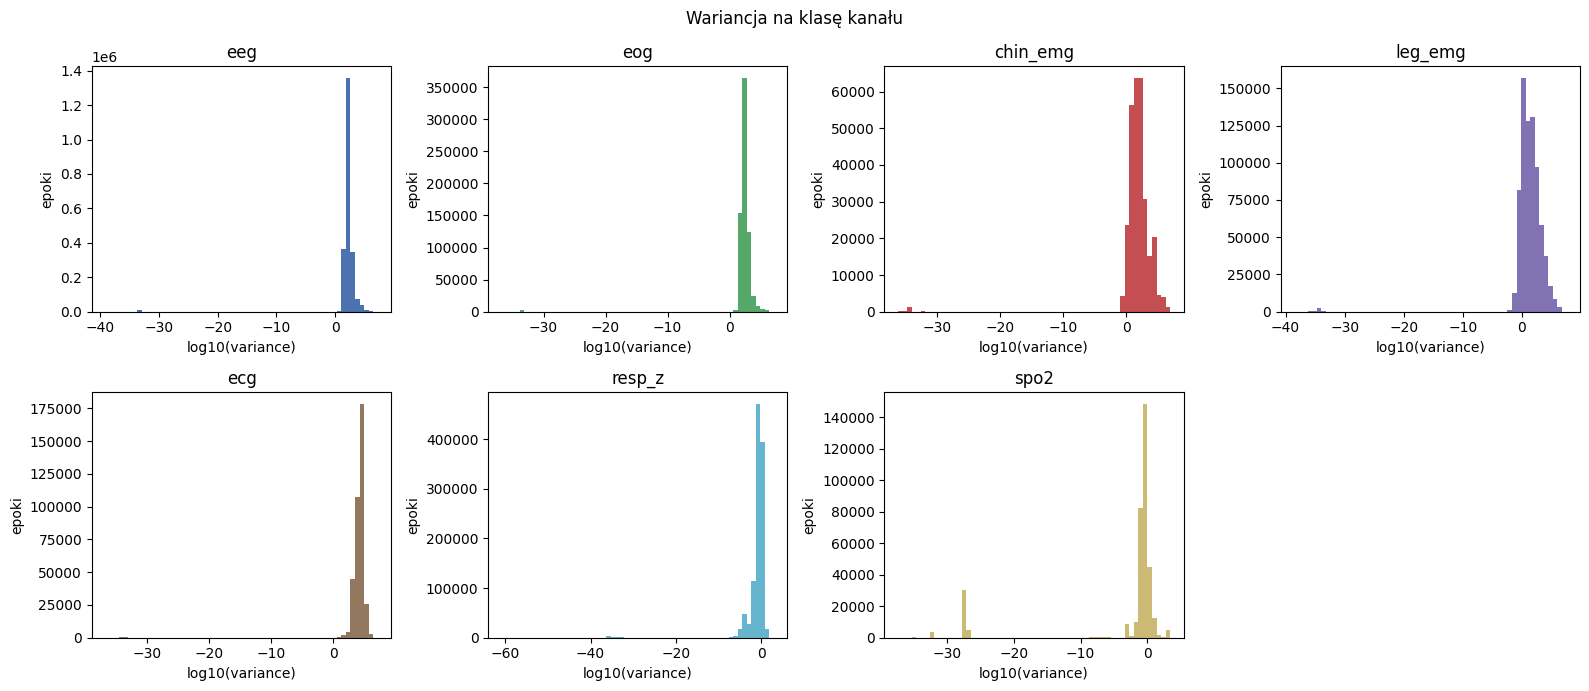

In [41]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, cls in zip(axes.ravel(), CLASSES):
    v = present.loc[present.channel_class == cls, "variance"]
    v = v[v > 0]
    ax.hist(np.log10(v), bins=60, color=PAL[cls])
    ax.set_title(cls)
    ax.set_xlabel("log10(variance)")
    ax.set_ylabel("epoki")
axes.ravel()[-1].axis("off")
fig.suptitle("Wariancja na klasę kanału")
plt.tight_layout()
plt.show()

In [42]:
zero_var = (present.assign(is_zero=present.variance == 0,
                           is_near=(present.variance > 0) & (present.variance < 1e-10))
            .groupby("channel_class")
            .agg(n_epok=("variance", "size"), zero=("is_zero", "sum"), near_zero=("is_near", "sum"))
            .reindex(CLASSES))
zero_var["zero_%"]      = (zero_var["zero"]      / zero_var["n_epok"] * 100).round(3)
zero_var["near_zero_%"] = (zero_var["near_zero"] / zero_var["n_epok"] * 100).round(3)
zero_var["flat_total_%"] = ((zero_var["zero"] + zero_var["near_zero"]) / zero_var["n_epok"] * 100).round(3)
zero_var

,n_epok,zero,near_zero,zero_%,near_zero_%,flat_total_%
channel_class,,,,,,
eeg,2209134,1222,9640,0.055,0.436,0.492
eog,688942,437,3184,0.063,0.462,0.526
chin_emg,289211,145,1550,0.050,0.536,0.586
leg_emg,736378,231,3575,0.031,0.485,0.517
ecg,368189,168,1062,0.046,0.288,0.334
resp_z,1104567,3445,8962,0.312,0.811,1.123
spo2,368189,12086,39802,3.283,10.810,14.093


Analizując rozkład wariancji w każdym kanale można zauważyć, że zdecydowana większość epok ma wariancję wahającą się w rzędzie wielkości adekwatnym dla danego typu sygnału (skala sygnału jest dość stabilna).  Epoki o skrajnie wysokiej wariancji właściwie nie występują, co potwierdza, że wartości sygnału utrzymują się w stabilnym zakresie. Niestety każdy z kanałów zawiera epoki z wariancją równą lub bardzo bliską 0, co oznacza, że te epoki nie niosą użytecznego sygnału. Biorąc to pod uwagę oznaczanie epok na pdostawie wariancji ograniczy się do wykluczania wycinków sygnałów o zerowej lub bardzo bliskiej zeru wartości tej metryki.

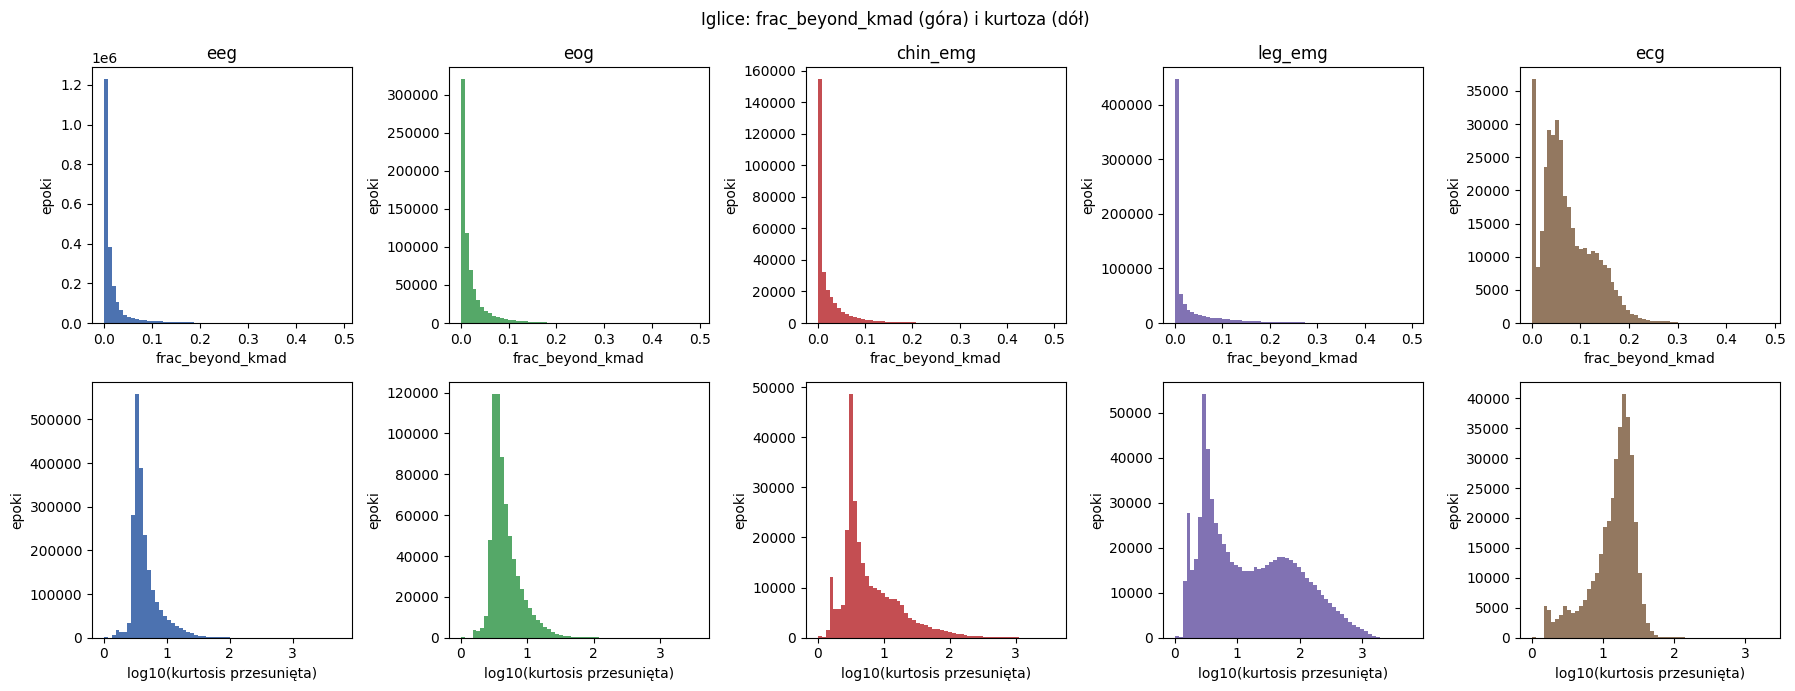

In [43]:
uvc = ["eeg", "eog", "chin_emg", "leg_emg", "ecg"]
fig, axes = plt.subplots(2, 5, figsize=(18, 7))
for ax, cls in zip(axes[0], uvc):
    fk = present.loc[present.channel_class == cls, "frac_beyond_kmad"].dropna()
    ax.hist(fk, bins=60, color=PAL[cls])
    ax.set_title(cls)
    ax.set_xlabel("frac_beyond_kmad")
    ax.set_ylabel("epoki")
for ax, cls in zip(axes[1], uvc):
    ku = present.loc[present.channel_class == cls, "kurtosis"].dropna()
    ku = ku[ku > -3]
    ax.hist(np.log10(ku - ku.min() + 1), bins=60, color=PAL[cls])
    ax.set_xlabel("log10(kurtosis przesunięta)")
    ax.set_ylabel("epoki")
fig.suptitle("Iglice: frac_beyond_kmad (góra) i kurtoza (dół)")
plt.tight_layout()
plt.show()

Iglice. frac_beyond_kmad to jeden słupek przy zerze i ogon opadający w prawo - bez ostrej granicy między epokami czystymi a iglastymi, więc progu nie odczytujemy z tego histogramu. Zostanie on dobrany ręcznie później, przy krzywych odrzutu, gdzie widać koszt każdej wartości i można odciąć ogon przy niewielkim odrzucie. ECG odstaje, bo załamki R są z natury ostre i metryka mierzy tu głównie rytm serca, a nie artefakty - jego próg potraktujemy ostrożnie. Kurtoza (dolny rząd) pokazuje to samo i służy tylko pomocniczo; o odrzuceniu epoki decyduje frac_beyond_kmad.

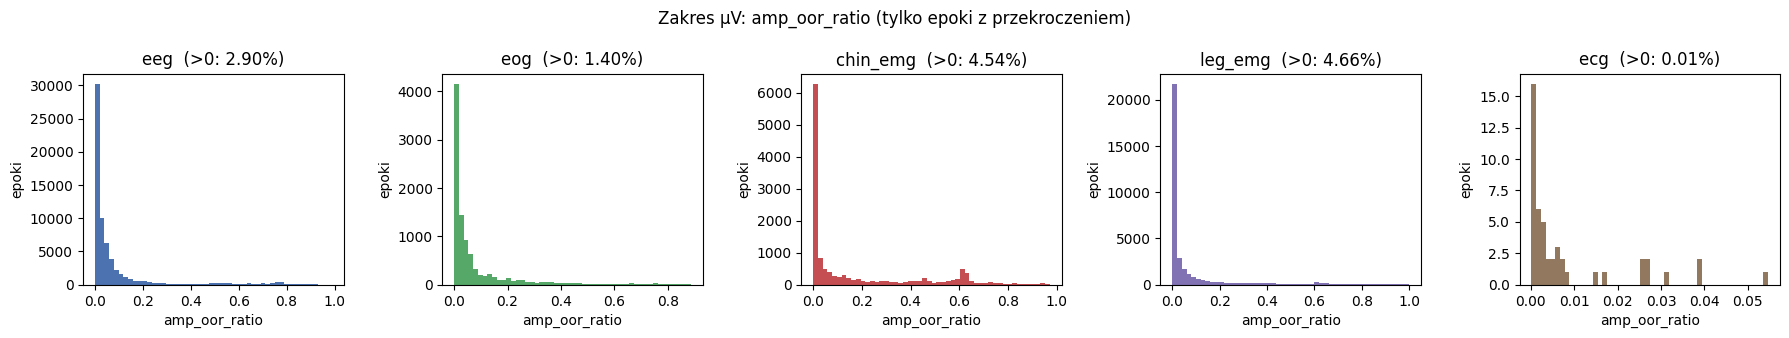

In [44]:
fig, axes = plt.subplots(1, 5, figsize=(18, 3.4))
for ax, cls in zip(axes, uvc):
    a = present.loc[present.channel_class == cls, "amp_oor_ratio"]
    nz = a[a > 0]
    ax.hist(nz, bins=50, color=PAL[cls])
    ax.set_title(f"{cls}  (>0: {100*len(nz)/len(a):.2f}%)")
    ax.set_xlabel("amp_oor_ratio")
    ax.set_ylabel("epoki")
fig.suptitle("Zakres µV: amp_oor_ratio (tylko epoki z przekroczeniem)")
plt.tight_layout()
plt.show()

Zdecydowana większość epok nie wychodzi poza swój naturalny zakres. Na podstawie tego można uznać, że wykonane pomiary są wiarygodne. Progi zostały ustalone na podstawie literatury, jednak zostały one znacząco zawyżone (kilkukrotność standardowych amplitud), żeby odseparować tylko te epoki, które z pewnością można oznaczyć jako artefakty sprzętowe, a nie lekkie zabrzuenie fizjologiczne. Wartości poza zakresem występują w niewielkim odsetku epok (widocznym w tytule każdego panelu), a sam histogram pokazuje rozkład jedynie wśród tych nielicznych epok z przekroczeniem - pozostałe, z zerowym amp_oor_ratio, są z niego pominięte

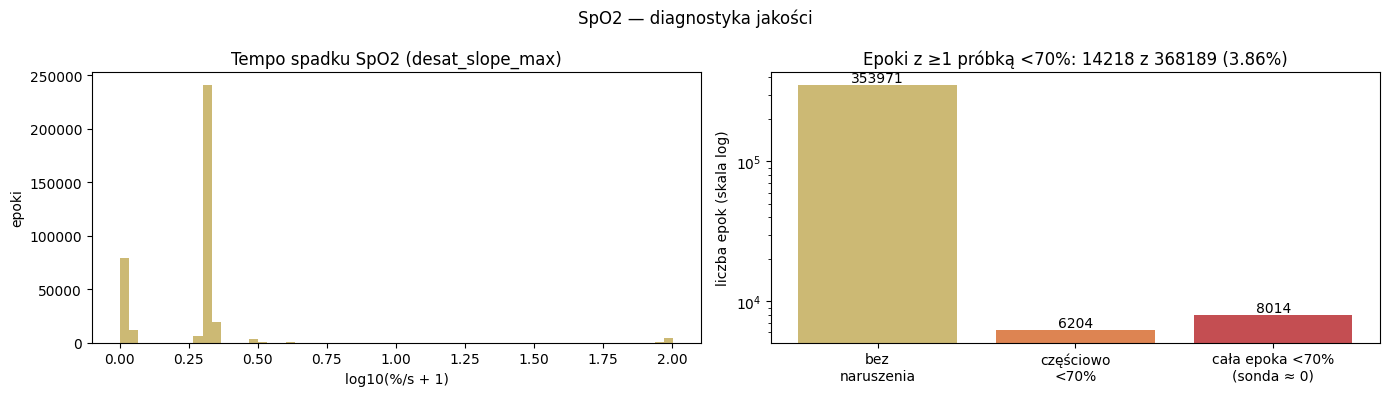

In [45]:
sp = present[present.channel_class == "spo2"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

d = sp.desat_slope_max.dropna()
axes[0].hist(np.log10(d + 1), bins=60, color=PAL["spo2"])
axes[0].set_title("Tempo spadku SpO2 (desat_slope_max)")
axes[0].set_xlabel("log10(%/s + 1)")
axes[0].set_ylabel("epoki")

pv = sp.physio_violation_ratio
n_total   = len(pv)
n_clean   = int((pv == 0).sum())
n_partial = int(((pv > 0) & (pv < 1.0)).sum())
n_full    = int((pv == 1.0).sum())
n_viol    = n_partial + n_full
bars = axes[1].bar(["bez\nnaruszenia", "częściowo\n<70%", "cała epoka <70%\n(sonda ≈ 0)"],
                   [n_clean, n_partial, n_full],
                   color=[PAL["spo2"], "#DD8452", "#C44E52"])
axes[1].set_yscale("log")
axes[1].set_ylabel("liczba epok (skala log)")
axes[1].set_title(f"Epoki z ≥1 próbką <70%: {n_viol} z {n_total} ({100*n_viol/n_total:.2f}%)")
axes[1].bar_label(bars, fmt="%d")

fig.suptitle("SpO2 — diagnostyka jakości")
plt.tight_layout()
plt.show()

Dodatkowe metryki pokazują, że w pomiarze saturacji zauważalna ilość epok ma spadki poniżej 70%. Całe epoki, zawierająca warości poniżej 70%, to ewidentne artefakty mówiące o nieprawidłowym działaniu sondy. Epoki, których całość znajduje się poniżej 70% zostaną oznaczone jako niepoprawne i wykluczone z dalszej analizy. Potwierdzenie, występowania takich zaburzeń sprzętowych można również znaleźć na pierwszym wykresie, na którym widać zauważalną ilość epok, w których spadki są bliskie 100%/s - są to odłączenia sondy. 

## 3.5 Krzywe odrzutu
Dla każdej metryki krzywa `rejection_rate(t)` z zaznaczonym zamrożonym progiem (koszt i kolano), a następnie odrzut łączny (union) z rozbiciem na tryby awarii.

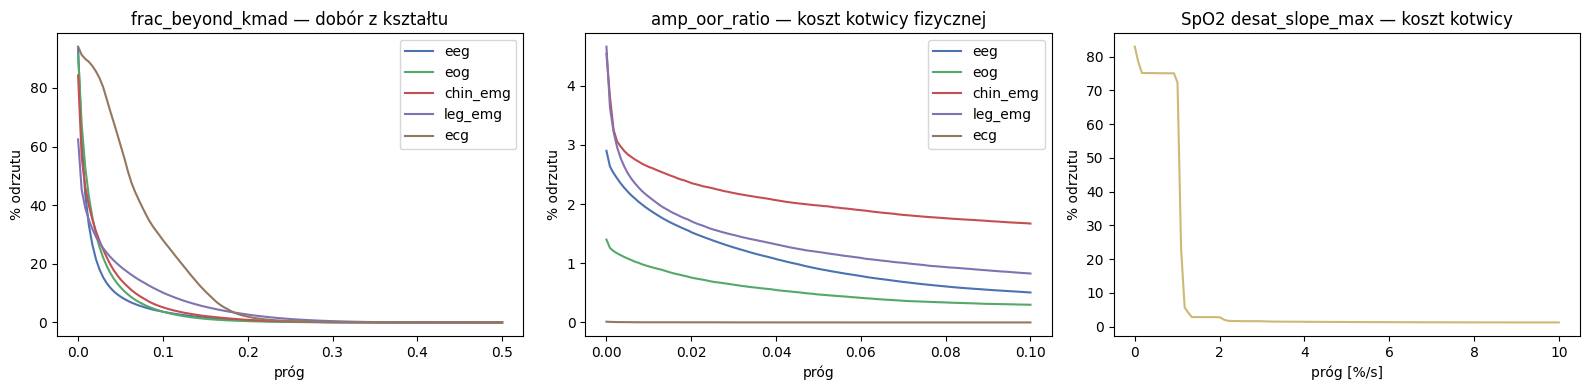

In [46]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

grid = np.linspace(0, 0.5, 120)
for cls in uvc:
    fk = present.loc[present.channel_class == cls, "frac_beyond_kmad"].dropna().to_numpy()
    axes[0].plot(grid, [(fk > t).mean() * 100 for t in grid], color=PAL[cls], label=cls)
axes[0].set_title("frac_beyond_kmad — dobór z kształtu")
axes[0].set_xlabel("próg"); axes[0].set_ylabel("% odrzutu"); axes[0].legend()

ag = np.linspace(0, 0.1, 120)
for cls in uvc:
    a = present.loc[present.channel_class == cls, "amp_oor_ratio"].to_numpy()
    axes[1].plot(ag, [(a > t).mean() * 100 for t in ag], color=PAL[cls], label=cls)
axes[1].set_title("amp_oor_ratio — koszt kotwicy fizycznej")
axes[1].set_xlabel("próg"); axes[1].set_ylabel("% odrzutu"); axes[1].legend()

dg = np.linspace(0, 10, 120)
d = present.loc[present.channel_class == "spo2", "desat_slope_max"].dropna().to_numpy()
axes[2].plot(dg, [(d > t).mean() * 100 for t in dg], color=PAL["spo2"])
axes[2].set_title("SpO2 desat_slope_max — koszt kotwicy")
axes[2].set_xlabel("próg [%/s]"); axes[2].set_ylabel("% odrzutu")

plt.tight_layout(); plt.show()

## 3.6 Progi
Użyte progi można podzielić na dwa rodzaje:
- Progi fizyczne: wynikają z fizjologii organizmu człowieka i są z góry ustalone na podstawie literatury medycznej. Zastosowane progi to kilkukrtność naturalnych zmian, jest to celowy zabieg, który ma na celu zapewnienie, że epoka odrzucana na podstawie tego progu jest na 100% błędem pomiarowym. Są to: amplitude_max_uv w sygnałach elektrofizjologicznych, physio_min w spo2 oraz flat_run_min_samples.
- Progi arbitralne: są określane na podstawie krzywych odrzutu wygenerowanych w poprzednim podpunkcie. Jest to wynik analizy wykresów, której celem było znalezienie progu możliwie najlepiej odrzucającego ogon epok artefaktowych przy jak najmniejszej stracie poprawnego sygnału. Ponieważ rozkład tych metryk jest ciągły i nie zawiera naturalnej granicy między epokami czystymi a zaszumionymi, próg nie wynika z żadnego automatycznego kryterium - wybrano go ręcznie, w miejscu, w którym krzywa odrzutu się wypłaszcza. Dotyczy to pzostałych metryk czyli: frac_beyond_kmad, amp_oor_ratio_max oraz desat_slope_max_pct_per_s.

In [47]:
TH = {
    "eeg":      {"amplitude_max_uv": 500.0,  "amp_oor_ratio_max": 0.01, "flat_var_min": 1.0,
                 "flat_run_min_samples": 200, "frac_beyond_kmad_max": 0.1},
    "eog":      {"amplitude_max_uv": 2000.0, "amp_oor_ratio_max": 0.01, "flat_var_min": 1.0,
                 "flat_run_min_samples": 200, "frac_beyond_kmad_max": 0.1},
    "chin_emg": {"amplitude_max_uv": 500.0, "amp_oor_ratio_max": 0.01, "flat_var_min": 0.1,
                 "flat_run_min_samples": 200, "frac_beyond_kmad_max": 0.1},
    "leg_emg":  {"amplitude_max_uv": 500.0, "amp_oor_ratio_max": 0.04, "flat_var_min": 0.1,
                 "flat_run_min_samples": 500, "frac_beyond_kmad_max": 0.15},
    "ecg":      {"amplitude_max_uv": 5000.0, "amp_oor_ratio_max": 0.01, "flat_var_min": 10.0,
                 "flat_run_min_samples": 200, "frac_beyond_kmad_max": 0.2},
    "resp_z":   {"flat_var_min": 0.0001, "flat_run_min_samples": 300},
    "spo2":     {"physio_min": 70.0, "desat_slope_max_pct_per_s": 2.25},
}
NAN_MAX = 0.0
pd.DataFrame(TH).T

,amplitude_max_uv,amp_oor_ratio_max,flat_var_min,flat_run_min_samples,frac_beyond_kmad_max,physio_min,desat_slope_max_pct_per_s
eeg,500.0,0.01,1.0000,200.0,0.10,NaN,NaN
eog,2000.0,0.01,1.0000,200.0,0.10,NaN,NaN
chin_emg,500.0,0.01,0.1000,200.0,0.10,NaN,NaN
leg_emg,500.0,0.04,0.1000,500.0,0.15,NaN,NaN
ecg,5000.0,0.01,10.0000,200.0,0.20,NaN,NaN
resp_z,NaN,NaN,0.0001,300.0,NaN,NaN,NaN
spo2,NaN,NaN,NaN,NaN,NaN,70.0,2.25


In [48]:
def add_quality_flags(df):
    out = []
    for cls, g in df.groupby("channel_class"):
        g = g.copy()
        t = TH[cls]
        fail_nan = g.nan_ratio > NAN_MAX
        if cls in UV_CLASSES:
            fail_flat = (g.variance < t["flat_var_min"]) | (g.flat_max_run >= t["flat_run_min_samples"])
            fail_amp = g.amp_oor_ratio > t["amp_oor_ratio_max"]
            fail_chaos = g.frac_beyond_kmad > t["frac_beyond_kmad_max"]
            g["fail_flat"], g["fail_amp"], g["fail_chaos"] = fail_flat, fail_amp, fail_chaos
            g["bad"] = fail_nan | fail_flat | fail_amp | fail_chaos
        elif cls == "resp_z":
            fail_flat = (g.variance < t["flat_var_min"]) | (g.flat_max_run >= t["flat_run_min_samples"])
            g["fail_flat"] = fail_flat
            g["bad"] = fail_nan | fail_flat
        else:
            fail_phys = g.physio_violation_ratio > 0
            fail_desat = g.desat_slope_max > t["desat_slope_max_pct_per_s"]
            g["fail_phys"], g["fail_desat"] = fail_phys, fail_desat
            g["bad"] = fail_nan | fail_phys | fail_desat
        out.append(g)
    return pd.concat(out, ignore_index=True)


flagged = add_quality_flags(present)
flagged.bad.mean().round(4)

np.float64(0.0549)

Po nałożeniu progów i nadaniu etykiet jakościowych epokom okazało się, że na podstawie tych kryteriów 5,49% wszystkich epok została uznana za wadliwe. Wyklczenie ich nie spowoduje drastycznego spadku w ilości danych, a znacznie poprawi jakość analizy.

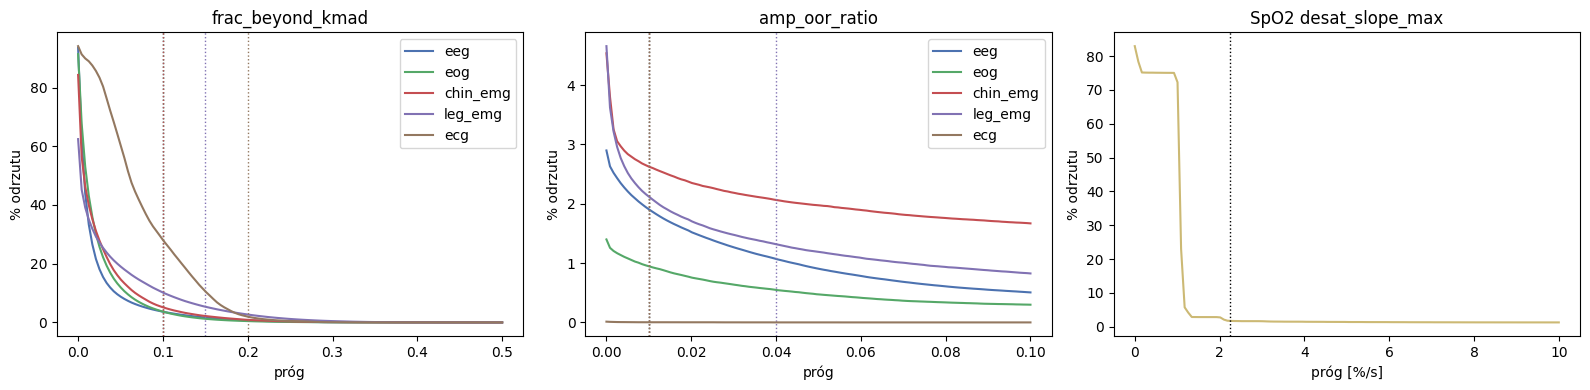

In [49]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

grid = np.linspace(0, 0.5, 120)
for cls in uvc:
    fk = present.loc[present.channel_class == cls, "frac_beyond_kmad"].dropna().to_numpy()
    axes[0].plot(grid, [(fk > t).mean() * 100 for t in grid], color=PAL[cls], label=cls)
    axes[0].axvline(TH[cls]["frac_beyond_kmad_max"], color=PAL[cls], ls=":", lw=1)
axes[0].set_title("frac_beyond_kmad"); axes[0].set_xlabel("próg"); axes[0].set_ylabel("% odrzutu"); axes[0].legend()

ag = np.linspace(0, 0.1, 120)
for cls in uvc:
    a = present.loc[present.channel_class == cls, "amp_oor_ratio"].to_numpy()
    axes[1].plot(ag, [(a > t).mean() * 100 for t in ag], color=PAL[cls], label=cls)
    axes[1].axvline(TH[cls]["amp_oor_ratio_max"], color=PAL[cls], ls=":", lw=1)   # <-- per klasa
axes[1].set_title("amp_oor_ratio")
axes[1].set_xlabel("próg"); axes[1].set_ylabel("% odrzutu"); axes[1].legend()

dg = np.linspace(0, 10, 120)
d = present.loc[present.channel_class == "spo2", "desat_slope_max"].dropna().to_numpy()
axes[2].plot(dg, [(d > t).mean() * 100 for t in dg], color=PAL["spo2"])
axes[2].axvline(TH["spo2"]["desat_slope_max_pct_per_s"], color="k", ls=":", lw=1)
axes[2].set_title("SpO2 desat_slope_max"); axes[2].set_xlabel("próg [%/s]"); axes[2].set_ylabel("% odrzutu")

plt.tight_layout(); plt.show()

Linie odrzutu znalazły się w miejscach, w których krzywa zaczyna się wypłaszczać. Progi zostały dobrane w sposób właściwy i zachowuje on zdecydowaną większość danych, odrzucając tylko skrajnie niepoprawne wartości.

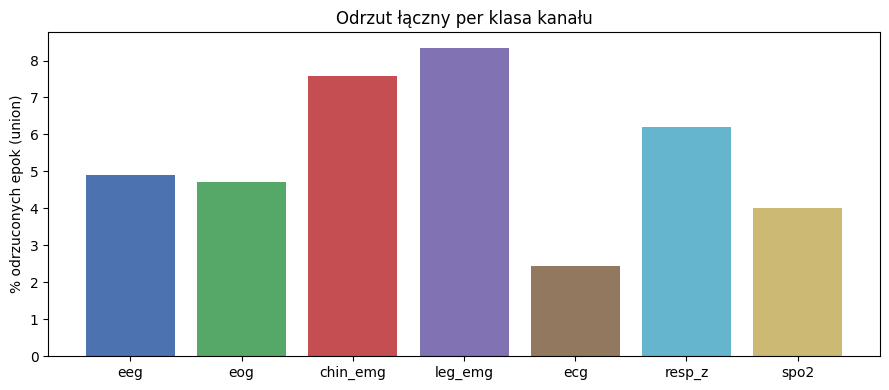

In [50]:
rej = (flagged.groupby("channel_class")
       .agg(union_=("bad", "mean"))
       .mul(100).rename(columns={"union_": "union_%"})
       .reindex(CLASSES))

fig, ax = plt.subplots(figsize=(9, 4))
u = rej["union_%"].dropna()
ax.bar(u.index, u.values, color=[PAL[c] for c in u.index])
ax.set_ylabel("% odrzuconych epok (union)")
ax.set_title("Odrzut łączny per klasa kanału")
plt.tight_layout()
plt.show()

In [51]:
modes = ["fail_flat", "fail_amp", "fail_chaos", "fail_phys", "fail_desat"]
for m in modes:
    if m in flagged:
        rej[m] = flagged.groupby("channel_class")[m].mean().mul(100)
rej = rej.reindex(CLASSES).round(3)
rej

,union_%,fail_flat,fail_amp,fail_chaos,fail_phys,fail_desat
channel_class,,,,,,
eeg,4.900,0.645547,1.902963,3.637941,NaN,NaN
eog,4.707,0.646499,0.944927,3.672007,NaN,NaN
chin_emg,7.587,1.053902,2.624036,5.159901,NaN,NaN
leg_emg,8.345,2.345534,1.318073,5.343995,NaN,NaN
ecg,2.440,0.497027,0.002716,1.963937,NaN,NaN
resp_z,6.214,6.213747,NaN,NaN,NaN,NaN
spo2,4.020,NaN,NaN,NaN,3.861604,1.702115


Dla każdego rodzaj każde kryterium odrzuca dość niewielki odsetek sygnału. Oznacza to, że progi nie są zbyt surwe i wykrywają realne zaburzenia sprzętowe. Najwyższy odrzut mają kanały EMG (chin i leg), głównie spowodowane kryterium kMAD, co wynika z natury sygnału: EMG jest z natury iglaste, więc detektor iglic reaguje na nie częściej niż na pozostałe sygnały.

## 3.7 Odrzut per klasa zaburzeń i placówka
Ta sekcja ma na celu zbadanie, czy jakość sygnału fizjologicznych w jakiś sposób koreluje ze zmienną opisywaną - Cognitive_Impairment. Jest to ważne ze względu na to, że gdyby jedna z grup (np. osoby z zaburzeniami) miała systematycznie wyższy odrzut, to filtr jakości sam w sobie niósłby informację o klasie. Model mógłby się wtedy nauczyć rozpoznawać target po tym, ile danych komu odrzucono, a nie po faktycznej fizjologii snu - a to byłby wyciek zawyżający wyniki.

In [52]:
rej_target = (flagged.groupby(["channel_class", "Cognitive_Impairment"]).bad.mean()
              .mul(100).unstack().reindex(CLASSES).round(3))
rej_target

Cognitive_Impairment,False,True
channel_class,,
eeg,4.795,5.004
eog,4.808,4.608
chin_emg,7.824,7.346
leg_emg,7.635,9.046
ecg,3.154,1.736
resp_z,6.687,5.747
spo2,4.186,3.855


In [53]:
rej_site = (flagged.groupby(["channel_class", "SiteID"]).bad.mean()
            .mul(100).unstack().reindex(CLASSES).round(3))
rej_site

SiteID,I0002,I0006,S0001
channel_class,,,
eeg,6.687,8.286,4.043
eog,NaN,6.832,4.262
chin_emg,7.610,10.037,6.875
leg_emg,6.999,11.311,7.837
ecg,10.110,4.117,1.451
resp_z,1.039,6.093,6.670
spo2,4.739,5.454,3.660


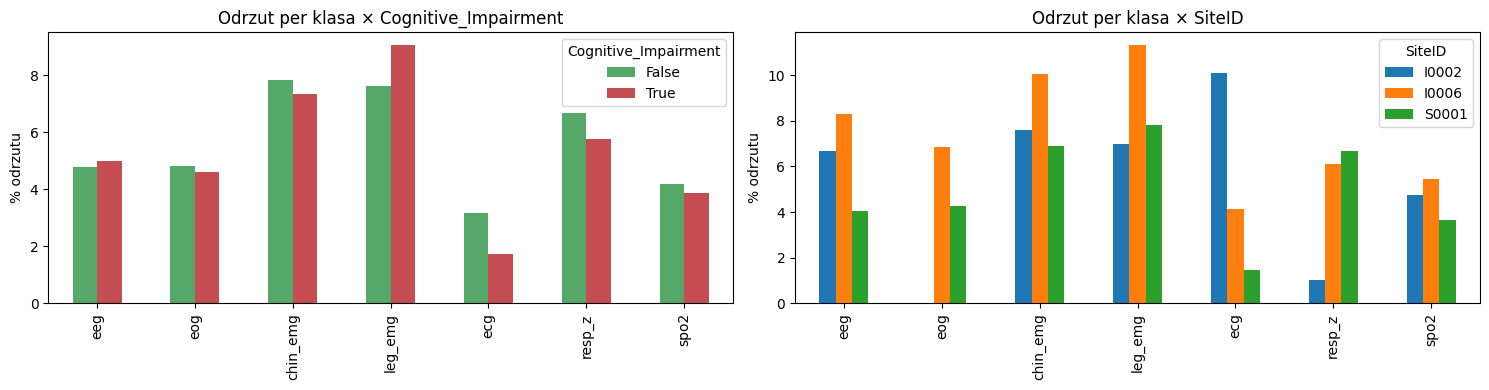

In [54]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
rej_target.plot(kind="bar", ax=axes[0], color=["#55A868", "#C44E52"])
axes[0].set_title("Odrzut per klasa × Cognitive_Impairment")
axes[0].set_ylabel("% odrzutu")
axes[0].set_xlabel("")
axes[0].legend(title="Cognitive_Impairment")
rej_site.plot(kind="bar", ax=axes[1])
axes[1].set_title("Odrzut per klasa × SiteID")
axes[1].set_ylabel("% odrzutu")
axes[1].set_xlabel("")
axes[1].legend(title="SiteID")
plt.tight_layout()
plt.show()

In [55]:
import scipy.stats as st

per_pac = (flagged.groupby(["channel_class", "patient_id"])
           .agg(rej=("bad", "mean")).reset_index())
ci = (pd.read_csv(DEMOGRAPHICS_CSV)
      .set_index("BidsFolder")["Cognitive_Impairment"])
per_pac["ci"] = per_pac.patient_id.map(ci).astype(int)

for cls in CLASSES:
    d = per_pac[per_pac.channel_class == cls]
    if d.ci.nunique() < 2:
        continue
    r = st.pointbiserialr(d.ci, d.rej)[0]
    print(f"{cls:9s}  r={r:+.3f}")

eeg        r=+0.019
eog        r=-0.026
chin_emg   r=-0.023
leg_emg    r=+0.068
ecg        r=-0.080
resp_z     r=-0.048
spo2       r=-0.034


Liczba odrzuceń epok nie jest wyraźnie obciążona ani w kierunku wartości zmiennej opisywanej ani placówki. Odsetek odrzuconych u pacjenta epok na kanał wykazuje niemalże zerową korelację z zaburzeniami poznawczymi. Oznacza to, że filtr jest neutralny względem klasy i nie powinien wyciec do modelu.

## 3.8 Zamrożenie progów
Progi zapisujemy do references/quality_thresholds.json i posłużą one jako twarde kryteria podczas przetwarzania do warstwy gold.

In [56]:
quality_payload = {
    "channel_class_thresholds": TH,
    "channel_to_class": CLASS_OF,
}
out_path = SPLITS_DIR / "quality_thresholds.json"
out_path.write_text(json.dumps(quality_payload, indent=2, ensure_ascii=False))

1583

## Podsumowanie
Analiza wykazała słuszność zastosowania metryk jakościowych na epokach. Wiele kanałów zawiera epoki, które mają ciągłe sygnały lub wartości zupełnie nienaturalne dla danego typu zjawiska, które było mierzone. Wykluczenie tych epok usuwa z dalszej analizy materiał obarczony artefaktami sprzętowymi przy stracie jedynie około 5% jednostek epoka-kanał. Odrzucanie epok odbędzie się na podstawie progów zdefiniowanych w oparciu o właściwości fizjologicznych danego zjawiska mierzonego i oceny ludzkiej, wykonanej na podstawie krzywych odrzutu. Dodatkowo zostało zweryfikowane, że jakość sygnału nie wycieknie do modelu jako cecha opisująca. Metryki, które będą dokonywały ostatecznego odrzutu: 
- dla danych elektrofizjologicznych: amplitude_max_uv, amp_oor_ratio_max, flat_var_min, flat_run_min_samples, frac_beyond_kmad_max;
- dla danych oddechowych: tylko flat_var_min, flat_run_min_samples;
- dla kanału saturacji (spO2): physio_min, desat_slope_max_pct_per_s.